In [1]:
## 1. Imports and settings
import pandas as pd
import numpy as np
import seaborn as sns
import ptitprince as pt
import statsmodels.api as sm
from sklearn.model_selection import ShuffleSplit
from statsmodels.stats.multitest import fdrcorrection
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from pathlib import Path
from pygam import LinearGAM, s, f, l
import enigmatoolbox.datasets as enigma_datasets

from IPython.display import display
from scipy.stats import ttest_ind
from enigmatoolbox.utils.parcellation import parcel_to_surface
from brainspace import mesh
from brainspace.plotting import plot_hemispheres

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 10,
    'axes.titlesize': 10,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

DATA_DIR = Path('/data/pt_03279/epilepsy_project/Epilepsy')
COHORT = 'GGE'
TEST_SIZE = .30
SEED = 42
ROI = 'L_entorhinal'
AGE_BINS = [18, 30, 45, 66]
AGE_LABELS = ['18-29', '30-44', '45-65']
RUN_TAG = f'AgeSexICV_PI95_RandomHC{round(100 * (1 - TEST_SIZE))}_seed{SEED}'
OUT_ROOT = Path('GAM_results_v2')
OUT_DIR = OUT_ROOT / COHORT / RUN_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert 0 < TEST_SIZE < 1

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()


In [2]:
## 2. Load data and split healthy controls
demo = pd.read_csv(DATA_DIR / 'demo.csv', index_col=0)
tle = pd.read_csv(DATA_DIR / 'ctx_tle.csv', index_col=0).astype(float)
gge = pd.read_csv(DATA_DIR / 'ctx_ige.csv', index_col=0).astype(float)
assert demo.index.is_unique and tle.index.is_unique and gge.index.is_unique
assert tle.columns.is_unique and gge.columns.is_unique
assert set(tle.columns) == set(gge.columns)

controls = tle.loc[pd.to_numeric(demo.loc[tle.index, 'Dx']).eq(0)]
patients = gge.loc[pd.to_numeric(demo.loc[gge.index, 'Dx']).eq(1), tle.columns]
assert len(controls) == 705, 'Expected the 705 TLE healthy controls.'
ctx = pd.concat([controls, patients])
assert ctx.index.is_unique and ctx.columns.is_unique
assert ctx.shape[1] == 68 and np.isfinite(ctx.to_numpy()).all()
dem = demo.loc[ctx.index].copy()
dem[['Age', 'Sex', 'ICV', 'Dx', 'SDx']] = dem[
    ['Age', 'Sex', 'ICV', 'Dx', 'SDx']].apply(pd.to_numeric, errors='raise')
X = dem[['Age', 'Sex', 'ICV']].to_numpy(dtype=float)
assert np.isfinite(X).all()
assert dem.Dx.isin([0, 1]).all() and dem.Sex.isin([1, 2]).all()
hc = dem.Dx.eq(0)

## Random Train–Test
train_ids, test_ids = train_test_split(
    dem.index[hc].to_numpy(),
    test_size=TEST_SIZE,
    random_state=SEED
)
train = dem.index.isin(train_ids)
test = dem.index.isin(test_ids)
assert train.any() and test.sum() >= 2 and set(dem.loc[train, 'Sex']) == {1, 2}
analysis_ids = dem.index[~train]
split_info = dem[['Age', 'Sex', 'ICV', 'Dx', 'SDx']].copy()
split_info['Role'] = np.select([train, test], ['HC_train', 'HC_test'], default='patient')
split_info['Age_extrapolated'] = ~dem.Age.between(*dem.loc[train, 'Age'].agg(['min', 'max']))
print(split_info.Role.value_counts())

Role
HC_train    493
patient     215
HC_test     212
Name: count, dtype: int64


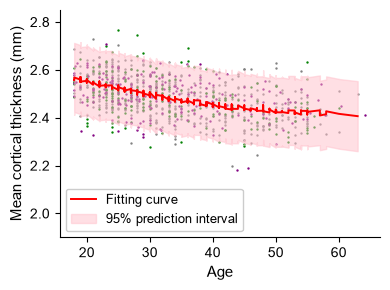

In [3]:
## 3. Mean Cortical Thickness: GAM Demonstration
mean_ct = ctx.mean(axis=1)
mean_gam = LinearGAM(s(0) + f(1) + l(2)).gridsearch(
    X[train], mean_ct.loc[train].to_numpy(), progress=False
)

assert mean_gam.logs_['diffs'][-1] < mean_gam.tol, 'Mean CT GAM did not converge.'

age_sex = X[train]
mean = mean_gam.predict(age_sex)
ci = mean_gam.prediction_intervals(age_sex, width=.95)
rank = age_sex[:, 0].argsort()

with plt.rc_context({
    'font.size': 10,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
    'axes.linewidth': .8
}):
    fig, ax = plt.subplots(figsize=(4, 3.0))

    for mask, color in [(train, 'grey'), (test, 'green'), (~hc, 'purple')]:
        ax.scatter(
            dem.loc[mask, 'Age'], mean_ct.loc[mask],
            color=color, s=.5
        )

    ax.plot(
        age_sex[:, 0][rank], mean[rank],
        color='red', lw=1.4, label='Fitting curve'
    )
    ax.fill_between(
        age_sex[:, 0][rank], ci[:, 0][rank], ci[:, 1][rank],
        color='pink', alpha=.5, label='95% prediction interval'
    )

    ax.set(
        xlabel='Age',
        ylabel='Mean cortical thickness (mm)',
        ylim=(1.9, 2.85),
        xticks=[20, 30, 40, 50, 60],
        yticks=[2.0, 2.2, 2.4, 2.6, 2.8]
    )
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(
        loc='lower left', frameon=True,
        facecolor='white', framealpha=1
    )

    fig.tight_layout()
    fig.savefig(
        OUT_DIR / '01_Mean_CT_GAM.png',
        transparent=True, dpi=300, bbox_inches='tight'
    )
    plt.show()

mean_pi = mean_gam.prediction_intervals(X, width=.95)
mean_ct_results = pd.DataFrame({
    'Observed': mean_ct,
    'Predicted': mean_gam.predict(X),
    'PI_low': mean_pi[:, 0],
    'PI_high': mean_pi[:, 1]
})

In [4]:
## 4. Regional GAMs, deviation scores 
models, predicted, pi_width = {}, ctx.copy(), ctx.copy()
for region in ctx:
    gam = LinearGAM(s(0) + f(1) + l(2)).gridsearch(
        X[train], ctx.loc[train, region].to_numpy(), progress=False)
    assert gam.logs_['diffs'][-1] < gam.tol, f'No convergence: {region}'
    models[region] = gam
    predicted[region] = gam.predict(X)
    pi = gam.prediction_intervals(X, width=.95)
    pi_width[region] = pi[:, 1] - pi[:, 0]
ctx_resid = ctx - predicted
assert pi_width.gt(0).all().all()
ctx_z = 4 * ctx_resid / pi_width
assert np.isfinite(ctx_z.to_numpy()).all()

## Held-Out Healthy Control Validation
qc = pd.DataFrame({
    'RMSE_mm': ctx_resid.loc[test].pow(2).mean().pow(.5),
    'Deviation_mean': ctx_z.loc[test].mean(),
    'Deviation_SD': ctx_z.loc[test].std(),
    'PI95_coverage': ctx_resid.loc[test].abs().le(
        pi_width.loc[test] / 2
    ).mean()
})
display(qc.round(3))
main_model_diagnostics = pd.DataFrame({
    r: {'EDOF': m.statistics_['edof'], 'GCV': m.statistics_['GCV'],
        'Explained_deviance': m.statistics_['pseudo_r2']['explained_deviance'],
        'Final_diff': m.logs_['diffs'][-1]}
    for r, m in models.items()
}).T
main_model_diagnostics.to_csv(OUT_DIR / 'main_model_diagnostics.csv')
# Summary p-values are not used for inference.
models[ROI].summary()

,RMSE_mm,Deviation_mean,Deviation_SD,PI95_coverage
L_bankssts,0.146,-0.007,1.009,0.925
L_caudalanteriorcingulate,0.208,0.133,1.039,0.948
L_caudalmiddlefrontal,0.128,-0.001,1.061,0.920
L_cuneus,0.138,-0.120,1.047,0.939
L_entorhinal,0.321,-0.176,1.131,0.920
...,...,...,...,...
R_supramarginal,0.120,-0.132,1.063,0.934
R_frontalpole,0.203,0.001,1.066,0.929
R_temporalpole,0.359,-0.065,1.097,0.929
R_transversetemporal,0.195,0.123,1.046,0.948


LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                       4.336
Link Function:                     IdentityLink Log Likelihood:                                   -78.4522
Number of Samples:                          493 AIC:                                              167.5766
                                                AICc:                                             167.7155
                                                GCV:                                                0.0825
                                                Scale:                                               0.285
                                                Pseudo R-Squared:                                   0.0249
Feature Function                  Lam

/tmp/ipykernel_218015/1834134011.py:34: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  models[ROI].summary()


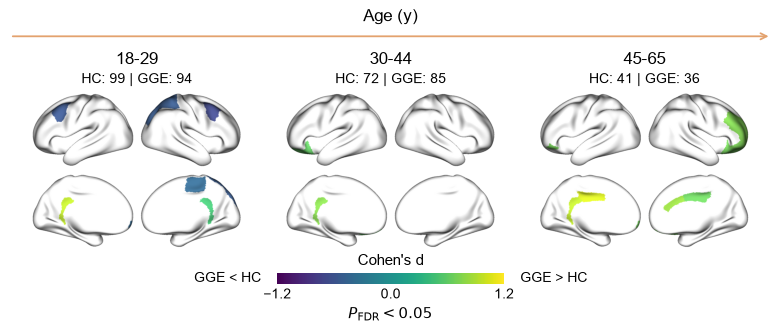

,Group,HC_test,Patients
0,All,212,215
1,Age_18-29,99,94
2,Age_30-44,72,85
3,Age_45-65,41,36
4,Female,117,137
5,Male,95,78


,Group,Region,N_HC,N_Patients,HC_mean,Patient_mean,Cohen_d,T,P,P_FDR
4,All,L_entorhinal,212,215,-0.176,0.142,0.301,3.105,0.002,0.011
72,Age_18-29,L_entorhinal,99,94,-0.147,0.123,0.252,1.764,0.079,0.245
140,Age_30-44,L_entorhinal,72,85,-0.223,0.287,0.487,3.028,0.003,0.053
208,Age_45-65,L_entorhinal,41,36,-0.162,-0.150,0.011,0.049,0.961,0.988
276,Female,L_entorhinal,117,137,-0.210,0.039,0.227,1.782,0.076,0.235
344,Male,L_entorhinal,95,78,-0.133,0.324,0.464,3.104,0.002,0.012


In [5]:
## 5. Regional Deviation Maps
surfaces = {h: mesh.mesh_io.read_surface(f'src/mesh/fs_LR.32k.{h}.inflated.surf.gii')
            for h in ['L', 'R']}
root = Path(enigma_datasets.__file__).parent
atlas = np.loadtxt(root / 'parcellations/aparc_conte69.csv', dtype=int)
roi_order = pd.read_csv(root / 'summary_statistics/scz_case-controls_CortThick.csv').Structure.tolist()
assert len(roi_order) == 68 and set(roi_order) == set(ctx_z.columns)
assert atlas.size == sum(s.n_points for s in surfaces.values()) and ctx_z.index.equals(dem.index)

age_group = pd.cut(dem.Age, AGE_BINS, labels=AGE_LABELS, right=False)
groups = {'All': pd.Series(True, index=dem.index),
          **{f'Age_{a}': age_group.eq(a) for a in AGE_LABELS},
          'Female': dem.Sex.eq(2), 'Male': dem.Sex.eq(1)}
rows, counts = [], []
for name, mask in groups.items():
    hc_z = ctx_z.loc[mask & test, roi_order]
    patient_z = ctx_z.loc[mask & dem.Dx.eq(1), roi_order]
    n_hc, n_pat = len(hc_z), len(patient_z)
    counts.append([name, n_hc, n_pat])
    if min(n_hc, n_pat) < 2:
        print(f'Skipped {name}: fewer than 2 participants in a comparison group.')
        continue
    pooled_sd = np.sqrt(((n_hc - 1) * hc_z.var() + (n_pat - 1) * patient_z.var())
                        / (n_hc + n_pat - 2))
    cohen_d = (patient_z.mean() - hc_z.mean()) / pooled_sd
    t, p = ttest_ind(patient_z, hc_z, axis=0, equal_var=False)
    assert np.isfinite(np.r_[cohen_d, p]).all(), name
    rows.append(pd.DataFrame({
        'Group': name, 'Region': roi_order, 'N_HC': n_hc, 'N_Patients': n_pat,
        'HC_mean': hc_z.mean().to_numpy(), 'Patient_mean': patient_z.mean().to_numpy(),
        'Cohen_d': cohen_d.to_numpy(), 'T': t, 'P': p, 'P_FDR': fdrcorrection(p)[1]}))
regional_results = pd.concat(rows, ignore_index=True)
group_counts = pd.DataFrame(counts, columns=['Group', 'HC_test', 'Patients'])

mean_limit = max(.1, np.ceil(regional_results[['HC_mean', 'Patient_mean']].abs().to_numpy().max() * 10) / 10)
d_limit = max(.1, np.ceil(regional_results.Cohen_d.abs().max() * 10) / 10)
MEAN_RANGE, D_RANGE, D_CMAP = (-mean_limit, mean_limit), (-d_limit, d_limit), 'viridis'

def render_brain_map(values, path, cmap, limits, masked=False):
    plot_hemispheres(
        surf_lh=surfaces['L'], surf_rh=surfaces['R'],
        array_name=[parcel_to_surface(values.to_numpy(dtype=float), atlas, fill=np.nan)],
        size=(400, 300), cmap=cmap, color_range=limits, layout_style='grid', zoom=1.6,
        color_bar=False, nan_color=(1, 1, 1, 1) if masked else (.5, .5, .5, 1),
        interactive=False, screenshot=True, filename=str(path), transparent_bg=True, scale=(3, 3))

brain_files = {}
for name, result in regional_results.groupby('Group', sort=False):
    result = result.set_index('Region').loc[roi_order]
    maps = {'HC_mean': (result.HC_mean, 'RdBu_r', MEAN_RANGE),
            f'{COHORT}_mean': (result.Patient_mean, 'RdBu_r', MEAN_RANGE),
            'Cohen_d': (result.Cohen_d, D_CMAP, D_RANGE),
            'Cohen_d_FDR': (result.Cohen_d.where(result.P_FDR < .05), D_CMAP, D_RANGE)}
    for metric, (values, cmap, limits) in maps.items():
        path = OUT_DIR / f'{COHORT}_Regional_{name}_{metric}.png'
        render_brain_map(values, path, cmap, limits, masked=metric == 'Cohen_d_FDR')
        brain_files[name, metric] = path

def add_colorbar(fig, rect, cmap, limits, label=''):
    return fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(*limits), cmap=cmap),
                       cax=fig.add_axes(rect), orientation='horizontal',
                       ticks=[limits[0], 0, limits[1]], label=label)

with plt.rc_context({'font.size': 11, 'axes.labelsize': 11, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'text.color': 'black', 'axes.labelcolor': 'black',
                     'xtick.color': 'black', 'ytick.color': 'black'}):
    for metric, limits, cmap, label in [
        ('Mean_deviation', MEAN_RANGE, 'RdBu_r', 'Mean deviation score'),
        ('Cohen_d', D_RANGE, D_CMAP, "Cohen's d")]:
        fig = plt.figure(figsize=(3.2, .65))
        add_colorbar(fig, [.12, .48, .76, .20], cmap, limits, label)
        fig.savefig(OUT_DIR / f'{COHORT}_Colorbar_{metric}.png', dpi=300,
                    bbox_inches='tight', transparent=True)
        plt.close(fig)
    panel_ages = [a for a in AGE_LABELS if (f'Age_{a}', 'Cohen_d_FDR') in brain_files]
    if panel_ages:
        fig = plt.figure(figsize=(2.7 * len(panel_ages), 3.3), facecolor='white')
        width = .94 / len(panel_ages)
        for x, label in enumerate(panel_ages):
            name = f'Age_{label}'
            result = regional_results.loc[regional_results.Group.eq(name)].iloc[0]
            center = .03 + (x + .5) * width
            fig.text(center, .84, label, ha='center', va='center', fontsize=12)
            fig.text(center, .78, f'HC: {int(result.N_HC)} | {COHORT}: {int(result.N_Patients)}',
                     ha='center', va='center', fontsize=10)
            ax = fig.add_axes([.03 + x * width, .26, width, .49])
            ax.imshow(plt.imread(brain_files[name, 'Cohen_d_FDR']))
            ax.axis('off')
        age_axis = fig.add_axes([.03, .89, .94, .07], xlim=(0, 1), ylim=(0, 1))
        age_axis.axis('off')
        age_axis.annotate('', xy=(1, .3), xytext=(0, .3),
                          arrowprops={'arrowstyle': '->', 'color': '#e3a26e', 'lw': 1.3})
        fig.text(.5, .97, 'Age (y)', ha='center', va='center', fontsize=12)
        fig.text(.5, .23, "Cohen's d", ha='center', va='center', fontsize=11)
        cb = add_colorbar(fig, [.36, .16, .28, .035], D_CMAP, D_RANGE)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, pad=3, labelsize=10)
        fig.text(.34, .1775, f'{COHORT} < HC', ha='right', va='center', fontsize=10)
        fig.text(.66, .1775, f'{COHORT} > HC', ha='left', va='center', fontsize=10)
        fig.text(.5, .055, r'$P_{\mathrm{FDR}} < 0.05$', ha='center', fontsize=11)
        for ext in ['png', 'pdf']:
            fig.savefig(OUT_DIR / f'{COHORT}_Regional_age_Cohen_d_FDR.{ext}',
                        dpi=300, bbox_inches='tight', pad_inches=.12, transparent=True)
        plt.show()

regional_results.to_csv(OUT_DIR / 'regional_deviation_results.csv', index=False)
group_counts.to_csv(OUT_DIR / 'regional_group_counts.csv', index=False)
display(group_counts)
display(regional_results[regional_results.Region.eq(ROI)].round(3))


In [6]:
## 6. Psychiatric reference maps and individual RVI
map_specs = {'ADHD': ('adhd', 'CortThick_case_vs_controls_adult'),
    'ASD': ('asd', 'CortThick_case_vs_controls_meta_analysis'),
    'BD': ('bipolar', 'CortThick_case_vs_controls_adult'),
    'MDD': ('depression', 'CortThick_case_vs_controls_adult'),
    'OCD': ('ocd', 'CortThick_case_vs_controls_adult'),
    'SCZ': ('schizophrenia', 'CortThick_case_vs_controls')}
enigma_dir = Path(enigma_datasets.__file__).parent / 'summary_statistics'
ct_maps = {}
for name, (disorder, table_name) in map_specs.items():
    table = (pd.read_csv(enigma_dir / 'scz_case-controls_CortThick.csv') if name == 'SCZ'
             else enigma_datasets.load_summary_stats(disorder)[table_name])
    ct_maps[name] = pd.Series(table.d_icv.to_numpy(dtype=float), index=table.Structure)
CT_d = pd.concat(ct_maps, axis=1)
assert CT_d.index.is_unique and set(CT_d.index) == set(ctx_z.columns)
CT_d = CT_d.loc[ctx_z.columns]
assert np.isfinite(CT_d.to_numpy()).all()
RVI = pd.DataFrame({name: ctx_z.T.corrwith(CT_d[name]) for name in CT_d}, index=ctx_z.index)
assert np.isfinite(RVI.to_numpy()).all()
order = list(RVI.columns)
analysis_demo = dem.loc[analysis_ids].copy()
analysis_demo['Sex_binary'] = analysis_demo.Sex.eq(1).astype(int)
analysis_demo['Dx_x_Sex'] = analysis_demo.Dx * analysis_demo.Sex_binary
terms = ['Dx', 'Sex_binary', 'Dx_x_Sex']
rvi_data = RVI.loc[analysis_ids].join(analysis_demo)


,Disorder,Beta,CI_low,CI_high,T,P,P_FDR
0,ADHD,-0.017449,-0.059770,0.024873,-0.810386,0.418172,0.627258
1,ASD,0.006622,-0.035048,0.048293,0.312374,0.754910,0.754910
2,BD,0.011437,-0.027459,0.050332,0.577933,0.563615,0.676338
3,MDD,-0.060589,-0.105173,-0.016006,-2.671212,0.007848,0.047088
4,OCD,0.022723,-0.007873,0.053318,1.459768,0.145093,0.390142
5,SCZ,-0.024000,-0.060349,0.012350,-1.297767,0.195071,0.390142


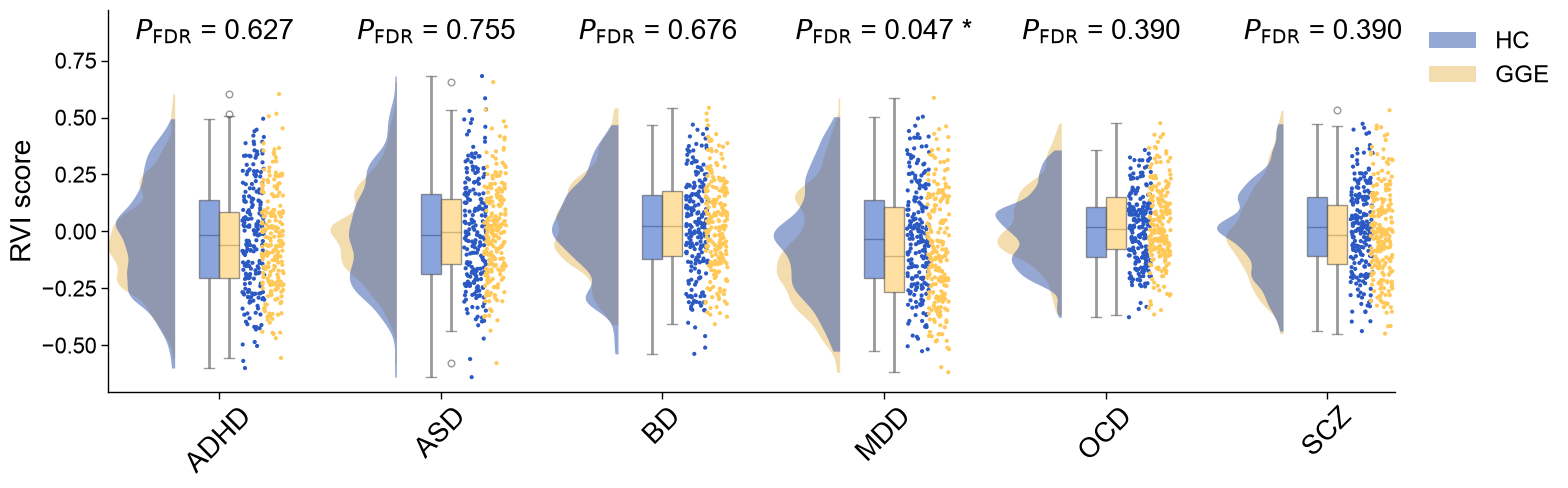

In [7]:
## 7. RVI: case-control differences and boxplots
def effect_table(outcomes, covariates, term):
    design = sm.add_constant(covariates.astype(float), has_constant='add')
    assert outcomes.index.equals(design.index)
    assert np.linalg.matrix_rank(design) == design.shape[1], 'Incomplete comparison groups.'
    rows = []
    for name in outcomes:
        fit = sm.OLS(outcomes[name], design, missing='raise').fit()
        low, high = fit.conf_int().loc[term]
        rows.append([name, fit.params[term], low, high, fit.tvalues[term], fit.pvalues[term]])
    result = pd.DataFrame(
        rows, columns=['Outcome', 'Beta', 'CI_low', 'CI_high', 'T', 'P']
    )
    result['P_FDR'] = fdrcorrection(result['P'])[1]
    return result

case_control_results = effect_table(rvi_data[order], rvi_data[['Dx']], 'Dx').rename(
    columns={'Outcome': 'Disorder'})
display(case_control_results)
star = lambda p: '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''
pfmt = lambda p: 'p<.001' if p < .001 else f'p={p:.3f}'

plot_df = rvi_data[['Dx'] + order].melt(
    id_vars='Dx', value_vars=order,
    var_name='Disorder', value_name='RVI'
)
plot_df['Group'] = plot_df.Dx.map({0: 'HC', 1: COHORT})
q = case_control_results.set_index('Disorder')['P_FDR']

sns.set_context('paper', font_scale=1.8)
np.random.seed(SEED)
fig, ax = plt.subplots(figsize=(16, 5.2))

pt.RainCloud(
    data=plot_df, x='Disorder', y='RVI', hue='Group',
    order=order, hue_order=['HC', COHORT],
    palette={'HC': '#2B59C3', COHORT: '#FFC857'},
    dodge=True, orient='v', width_viol=.6, width_box=.18,
    move=.2, point_size=3, alpha=.55, linewidth=0, ax=ax
)

low, high = ax.dataLim.intervaly
span = high - low
ax.set_yticks(np.arange(-1, 1.01, .25))
ax.set_ylim(low - .05 * span, high + .22 * span)

for x, disorder in enumerate(order):
    p = q[disorder]
    value = '< 0.001' if p < .001 else f'= {p:.3f}'
    ax.text(
        x, .98, r'$P_{\mathrm{FDR}}$' + f' {value} {star(p)}',
        transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=20, linespacing=1.1
    )

ax.set_xlabel('')
ax.set_ylabel('RVI score', fontsize=20)
ax.tick_params(axis='y', labelsize=16)
ax.margins(x=.04)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha='center', fontsize=20)
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:2], labels[:2], frameon=False, fontsize=17,
    loc='upper left', bbox_to_anchor=(1.01, 1)
)
save(fig, f'{COHORT}_vs_HC')

,Disorder,Beta,CI_low,CI_high,T,P,P_FDR
0,ADHD,-0.052992,-0.139606,0.033623,-1.202568,0.229816,0.275780
1,ASD,0.014769,-0.070655,0.100193,0.339824,0.734158,0.734158
2,BD,-0.083758,-0.162966,-0.004549,-2.078472,0.038268,0.062861
3,MDD,-0.110060,-0.200374,-0.019745,-2.395322,0.017040,0.051119
4,OCD,-0.080728,-0.141867,-0.019589,-2.595381,0.009777,0.051119
5,SCZ,-0.076815,-0.150806,-0.002825,-2.040638,0.041907,0.062861


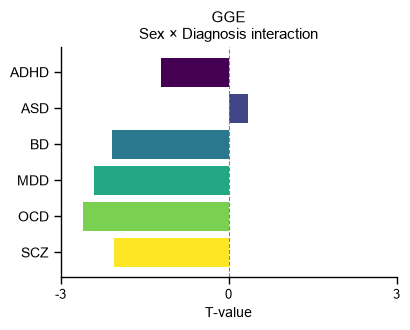

In [8]:
## 8. RVI: Sex × Dx Interaction
interaction_results = effect_table(
    rvi_data[order], rvi_data[terms], 'Dx_x_Sex'
).rename(columns={'Outcome': 'Disorder'})
display(interaction_results)

def interaction_plot(results, title, ax, limit=None):
    d = results.set_index('Disorder').loc[order]
    if limit is None:
        limit = max(.5, np.ceil(d['T'].abs().max() * 1.12 * 10) / 10)

    bars = ax.barh(
        d.index, d['T'],
        color=plt.cm.viridis(np.linspace(0, 1, len(order)))
    )
    ax.axvline(0, color='grey', ls='--', lw=.8)
    ax.set(
        xlim=(-limit, limit), xticks=[-limit, 0, limit],
        xticklabels=[f'{-limit:g}', '0', f'{limit:g}'],
        xlabel='T-value', title=title
    )

    for bar, p in zip(bars, d['P_FDR']):
        if p < .05:
            ax.text(
                bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f'FDR {pfmt(p)} {star(p)}',
                ha='center', va='center', fontsize=9,
                color='white' if bar.get_facecolor()[0] < .5 else 'black',
                fontweight='bold'
            )

    ax.spines[['top', 'right']].set_visible(False)
    ax.invert_yaxis()

with plt.rc_context({'font.size': 10, 'axes.titlesize': 11,
                     'axes.labelsize': 10, 'xtick.labelsize': 9,
                     'ytick.labelsize': 10}):
    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    interaction_plot(
        interaction_results,
        f'{COHORT}\nSex × Diagnosis interaction', ax
    )
    save(fig, f'{COHORT}_Sex_Dx')

Completed repeat 1/30
Completed repeat 2/30
Completed repeat 3/30
Completed repeat 4/30
Completed repeat 5/30
Completed repeat 6/30
Completed repeat 7/30
Completed repeat 8/30
Completed repeat 9/30
Completed repeat 10/30
Completed repeat 11/30
Completed repeat 12/30
Completed repeat 13/30
Completed repeat 14/30
Completed repeat 15/30
Completed repeat 16/30
Completed repeat 17/30
Completed repeat 18/30
Completed repeat 19/30
Completed repeat 20/30
Completed repeat 21/30
Completed repeat 22/30
Completed repeat 23/30
Completed repeat 24/30
Completed repeat 25/30
Completed repeat 26/30
Completed repeat 27/30
Completed repeat 28/30
Completed repeat 29/30
Completed repeat 30/30


,RMSE_mm_mean,RMSE_mm_std,Deviation_mean_mean,Deviation_mean_std,Deviation_SD_mean,Deviation_SD_std,PI95_coverage_mean,PI95_coverage_std
Region,,,,,,,,
L_bankssts,0.147,0.006,-0.015,0.065,1.022,0.066,0.944,0.017
L_caudalanteriorcingulate,0.203,0.008,-0.008,0.090,1.015,0.053,0.957,0.012
L_caudalmiddlefrontal,0.125,0.006,-0.007,0.094,1.027,0.069,0.946,0.020
L_cuneus,0.135,0.005,0.003,0.101,1.019,0.053,0.951,0.014
L_entorhinal,0.297,0.016,0.016,0.088,1.022,0.081,0.942,0.020
...,...,...,...,...,...,...,...,...
R_superiorparietal,0.105,0.004,0.017,0.084,1.007,0.054,0.950,0.015
R_superiortemporal,0.134,0.006,-0.019,0.090,0.993,0.070,0.958,0.013
R_supramarginal,0.115,0.005,-0.011,0.104,1.001,0.061,0.951,0.013


,Mean_SD,Max_SD,Mean_range,Mean_r_with_main,Min_r_with_main
Disorder,,,,,
ADHD,0.012,0.029,0.048,0.998,0.995
ASD,0.012,0.032,0.047,0.997,0.993
BD,0.011,0.023,0.042,0.998,0.994
MDD,0.011,0.027,0.045,0.999,0.997
OCD,0.008,0.016,0.030,0.998,0.995
SCZ,0.009,0.016,0.037,0.999,0.998


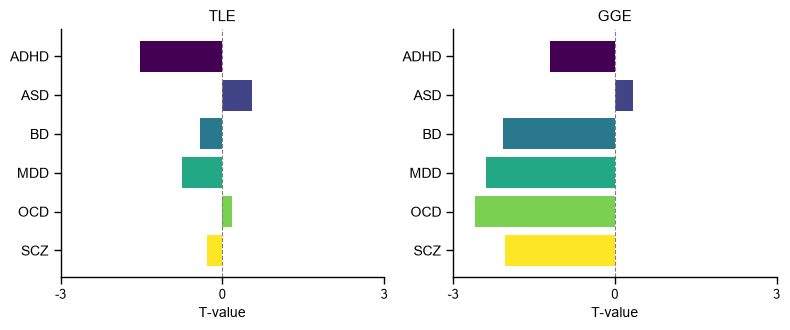

Saved: /data/pt_03279/epilepsy_project/Epilepsy/rvi-epilepsy-project-main/notebooks/GAM/GAM_results_v2/GGE/AgeSexICV_PI95_RandomHC70_seed42


In [9]:
## 9. Repeated Hold-Out Validation, RVI Stability and Save Results

# Save the main analysis first
tables = {
    'mean_CT_demo': mean_ct_results,
    'ctx_predicted': predicted,
    'PI95_width': pi_width,
    'ctx_z_all': ctx_z,
    'RVI_all': RVI,
    'RVI_analysis': rvi_data,
    'split_info': split_info,
    'reference_maps': CT_d,
    'HC_test_QC': qc,
    'main_model_diagnostics': main_model_diagnostics,
    'case_control_results': case_control_results,
    'interaction_results': interaction_results
}
for name, table in tables.items():
    table.to_csv(OUT_DIR / f'{name}.csv')

# Repeated random HC splits
N_REPEATS = 30
cv = ShuffleSplit(
    n_splits=N_REPEATS, test_size=TEST_SIZE, random_state=SEED
)
cv_hc_pos = np.flatnonzero(hc.to_numpy())
cv_patient_ids = dem.index[dem.Dx.eq(1)]
assert ctx.index.equals(dem.index) and ctx.columns.equals(CT_d.index)

cv_dir = OUT_DIR / 'CV_runs'
cv_dir.mkdir(parents=True, exist_ok=True)
cv_rows, cv_rvi_runs, cv_split_runs, cv_corrs = [], [], [], []
cv_columns = [
    'Run', 'Region', 'N_train', 'N_test', 'RMSE_mm',
    'Deviation_mean', 'Deviation_SD', 'PI95_coverage',
    'EDOF', 'GCV', 'Final_diff'
]

for cv_run, (cv_tr, cv_te) in enumerate(cv.split(cv_hc_pos), 1):
    cv_train, cv_test = cv_hc_pos[cv_tr], cv_hc_pos[cv_te]
    assert len(cv_test) >= 2 and set(dem.iloc[cv_train].Sex) == {1, 2}
    cv_z = ctx.copy()

    # Refit every regional GAM using only this split's training HC
    for cv_region in ctx:
        cv_y = ctx[cv_region].to_numpy()
        cv_model = LinearGAM(s(0) + f(1) + l(2)).gridsearch(
            X[cv_train], cv_y[cv_train], progress=False
        )
        cv_diff = cv_model.logs_['diffs'][-1]
        assert cv_diff < cv_model.tol, (
            f'No convergence: run {cv_run}, {cv_region}'
        )

        cv_pred = cv_model.predict(X)
        cv_pi = cv_model.prediction_intervals(X, width=.95)
        cv_width = cv_pi[:, 1] - cv_pi[:, 0]
        assert np.isfinite(cv_width).all() and (cv_width > 0).all()

        cv_z[cv_region] = 4 * (cv_y - cv_pred) / cv_width
        cv_resid = cv_y[cv_test] - cv_pred[cv_test]
        cv_test_z = cv_z[cv_region].iloc[cv_test]
        cv_coverage = (
            (cv_y[cv_test] >= cv_pi[cv_test, 0])
            & (cv_y[cv_test] <= cv_pi[cv_test, 1])
        ).mean()

        cv_rows.append([
            cv_run, cv_region, len(cv_train), len(cv_test),
            np.sqrt(np.mean(cv_resid ** 2)),
            cv_test_z.mean(), cv_test_z.std(), cv_coverage,
            cv_model.statistics_['edof'],
            cv_model.statistics_['GCV'], cv_diff
        ])

    # Recalculate RVI; retain only held-out HC and patients
    assert np.isfinite(cv_z.to_numpy()).all()
    cv_rvi = pd.DataFrame({
        name: cv_z.T.corrwith(CT_d[name]) for name in order
    }, index=ctx.index)
    assert np.isfinite(cv_rvi.to_numpy()).all()

    cv_eligible = np.ones(len(ctx), dtype=bool)
    cv_eligible[cv_train] = False
    cv_rvi = cv_rvi.loc[cv_eligible].rename_axis('ID')
    cv_rvi_runs.append(cv_rvi)
    cv_corrs.append(
        cv_rvi.loc[cv_patient_ids].corrwith(RVI.loc[cv_patient_ids])
    )

    # Record HC membership and save each completed repeat
    cv_roles = np.full(len(cv_hc_pos), 'HC_train', dtype=object)
    cv_roles[cv_te] = 'HC_test'
    cv_split_runs.append(pd.DataFrame({
        'Run': cv_run, 'ID': dem.index[cv_hc_pos], 'Role': cv_roles
    }))

    cv_rvi.to_csv(cv_dir / f'run_{cv_run:02}_RVI.csv')
    pd.DataFrame(
        cv_rows[-ctx.shape[1]:], columns=cv_columns
    ).to_csv(cv_dir / f'run_{cv_run:02}_QC.csv', index=False)
    cv_split_runs[-1].to_csv(
        cv_dir / f'run_{cv_run:02}_HC_split.csv', index=False
    )
    print(f'Completed repeat {cv_run}/{N_REPEATS}', flush=True)

# Summarize held-out validation across repeats
cv_validation = pd.DataFrame(cv_rows, columns=cv_columns)
cv_metrics = [
    'RMSE_mm', 'Deviation_mean', 'Deviation_SD', 'PI95_coverage'
]
cv_validation_summary = cv_validation.groupby('Region')[cv_metrics].agg(
    ['mean', 'std']
)
cv_validation_summary.columns = [
    f'{a}_{b}' for a, b in cv_validation_summary.columns
]
cv_splits = pd.concat(cv_split_runs, ignore_index=True)

# Within-person RVI stability
cv_rvi_all = pd.concat(
    cv_rvi_runs, keys=range(1, N_REPEATS + 1), names=['Run', 'ID']
)
cv_patient_corr = pd.DataFrame(
    cv_corrs, index=pd.Index(range(1, N_REPEATS + 1), name='Run')
)
cv_long = cv_rvi_all.reset_index().melt(
    id_vars=['Run', 'ID'], value_vars=order,
    var_name='Disorder', value_name='RVI'
)
rvi_stability = cv_long.groupby(
    ['ID', 'Disorder'], sort=False
).RVI.agg(
    N_runs='count', Mean='mean', SD='std', Min='min', Max='max'
).reset_index()
rvi_stability['Dx'] = rvi_stability.ID.map(dem.Dx)
rvi_stability['Range'] = rvi_stability.Max - rvi_stability.Min
assert rvi_stability.loc[
    rvi_stability.Dx.eq(1), 'N_runs'
].eq(N_REPEATS).all()

rvi_stability_summary = rvi_stability.loc[
    rvi_stability.Dx.eq(1)
].groupby('Disorder').agg(
    Mean_SD=('SD', 'mean'),
    Max_SD=('SD', 'max'),
    Mean_range=('Range', 'mean')
)
rvi_stability_summary['Mean_r_with_main'] = cv_patient_corr.mean()
rvi_stability_summary['Min_r_with_main'] = cv_patient_corr.min()

# Save validation and stability results
cv_tables = {
    'CV_HC_validation': cv_validation,
    'CV_HC_validation_summary': cv_validation_summary,
    'CV_HC_splits': cv_splits,
    'CV_RVI_all': cv_rvi_all,
    'CV_patient_RVI_correlations': cv_patient_corr,
    'CV_RVI_stability': rvi_stability,
    'CV_patient_RVI_stability_summary': rvi_stability_summary
}
for name, table in cv_tables.items():
    table.to_csv(OUT_DIR / f'{name}.csv')
tables.update(cv_tables)

display(cv_validation_summary.round(3))
display(rvi_stability_summary.round(3))

# Paired TLE–GGE interaction plot
paths = {
    name: OUT_ROOT / name / RUN_TAG / 'interaction_results.csv'
    for name in ['TLE', 'GGE']
}
if all(path.exists() for path in paths.values()):
    paired = {
        name: pd.read_csv(path, index_col=0)
        for name, path in paths.items()
    }
    for result in paired.values():
        result['P_FDR'] = fdrcorrection(result['P'])[1]

    limit = max(.5, np.ceil(
        max(d['T'].abs().max() for d in paired.values()) * 1.12 * 10
    ) / 10)

    with plt.rc_context({
        'font.size': 10, 'axes.titlesize': 11,
        'axes.labelsize': 10, 'xtick.labelsize': 9,
        'ytick.labelsize': 10
    }):
        fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
        for ax, (name, result) in zip(axes, paired.items()):
            interaction_plot(result, name, ax, limit)
        save(fig, 'TLE_GGE_Sex_Dx')
else:
    print('Paired plot pending: run both cohorts with the same RUN_TAG.')

print(f'Saved: {OUT_DIR.resolve()}')